# Unit 1: Sampling and probabilistic simulation

Covers: sampling with / without replacement, multiplication rule, conditional probability, law of total probability, Bayes' rule, and ROC / precision-recall curves under class imbalance.

Method every time: **(1)** state the rule, **(2)** compute the theoretical value, **(3)** simulate, **(4)** compare.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, auc, average_precision_score

random.seed(42)                      # reproducible results (remove to get a fresh run each time)
rng = np.random.default_rng(42)
N = 100_000                          # number of simulated trials

def check(name, empirical, theoretical, tol=0.01):
    ok = abs(empirical - theoretical) < tol
    print(f"{name:<45} empirical = {empirical:.4f} | theoretical = {theoretical:.4f} | {'OK' if ok else 'CHECK'}")

## 1. Sampling with and without replacement

Urn with 5 red (R) and 3 blue (B) balls, so $P(R)=5/8$. Draw two balls.

* **With replacement:** the draws are independent, $P(R_1\cap R_2)=P(R_1)P(R_2)=\left(\frac58\right)^2=\frac{25}{64}$.
* **Without replacement:** the second draw depends on the first. By the multiplication rule, $P(R_1\cap R_2)=P(R_1)\,P(R_2\mid R_1)=\frac58\cdot\frac47=\frac{5}{14}$.

In Python: `random.choices(pop, k=2)` samples **with** replacement, `random.sample(pop, 2)` samples **without**.

In [2]:
urn = ['R'] * 5 + ['B'] * 3

def sample_two(replace):
    return random.choices(urn, k=2) if replace else random.sample(urn, 2)

for replace, theory in [(True, (5/8) ** 2), (False, (5/8) * (4/7))]:
    both_red = sum(1 for _ in range(N) if sample_two(replace) == ['R', 'R'])
    label = "with replacement" if replace else "without replacement"
    check(f"P(both red), {label}", both_red / N, theory)

P(both red), with replacement                 empirical = 0.3883 | theoretical = 0.3906 | OK
P(both red), without replacement              empirical = 0.3574 | theoretical = 0.3571 | OK


## 2. Multiplication rule, conditional probability, total probability, Bayes

Two draws **without** replacement from the same urn. Let $R_1,B_1$ be the colour of the first ball and $R_2$ the event that the second ball is red.

* **Conditional probability:** $P(A\mid B)=\dfrac{P(A\cap B)}{P(B)}$, with $P(B)>0$.
* **Multiplication rule:** $P(A\cap B)=P(B)\,P(A\mid B)$.
* **Law of total probability** (the events $R_1,B_1$ partition the sample space):
$P(R_2)=P(R_2\mid R_1)P(R_1)+P(R_2\mid B_1)P(B_1)=\frac47\cdot\frac58+\frac57\cdot\frac38=\frac58$
* **Bayes' rule:** $P(R_1\mid R_2)=\dfrac{P(R_2\mid R_1)\,P(R_1)}{P(R_2)}=\dfrac{\frac47\cdot\frac58}{\frac58}=\frac47$

In [3]:
draws = [random.sample(urn, 2) for _ in range(N)]      # ordered pairs (first, second), no replacement

n_R1  = sum(1 for d in draws if d[0] == 'R')
n_B1  = sum(1 for d in draws if d[0] == 'B')
n_R2  = sum(1 for d in draws if d[1] == 'R')
n_R1R2 = sum(1 for d in draws if d[0] == 'R' and d[1] == 'R')
n_B1R2 = sum(1 for d in draws if d[0] == 'B' and d[1] == 'R')

P_R1, P_B1, P_R2 = n_R1 / N, n_B1 / N, n_R2 / N
P_R1_and_R2 = n_R1R2 / N
P_R2_given_R1 = n_R1R2 / n_R1          # definition: P(A and B) / P(B), computed from counts
P_R2_given_B1 = n_B1R2 / n_B1

print("--- Conditional probability ---")
check("P(R2 | R1)", P_R2_given_R1, 4/7)
check("P(R2 | B1)", P_R2_given_B1, 5/7)

print("\n--- Multiplication rule: P(R1 and R2) = P(R1) P(R2 | R1) ---")
check("P(R1 and R2) (counted directly)", P_R1_and_R2, 5/8 * 4/7)
check("P(R1) * P(R2 | R1) (from the rule)", P_R1 * P_R2_given_R1, 5/8 * 4/7)

print("\n--- Law of total probability ---")
total_prob = P_R2_given_R1 * P_R1 + P_R2_given_B1 * P_B1
check("P(R2) (counted directly)", P_R2, 5/8)
check("P(R2|R1)P(R1) + P(R2|B1)P(B1)", total_prob, 5/8)

print("\n--- Bayes' rule ---")
P_R1_given_R2_direct = n_R1R2 / n_R2                      # definition of conditional probability
P_R1_given_R2_bayes = P_R2_given_R1 * P_R1 / P_R2         # Bayes
check("P(R1 | R2) (counted directly)", P_R1_given_R2_direct, 4/7)
check("P(R2|R1)P(R1) / P(R2) (Bayes)", P_R1_given_R2_bayes, 4/7)

--- Conditional probability ---
P(R2 | R1)                                    empirical = 0.5726 | theoretical = 0.5714 | OK
P(R2 | B1)                                    empirical = 0.7140 | theoretical = 0.7143 | OK

--- Multiplication rule: P(R1 and R2) = P(R1) P(R2 | R1) ---
P(R1 and R2) (counted directly)               empirical = 0.3569 | theoretical = 0.3571 | OK
P(R1) * P(R2 | R1) (from the rule)            empirical = 0.3569 | theoretical = 0.3571 | OK

--- Law of total probability ---
P(R2) (counted directly)                      empirical = 0.6259 | theoretical = 0.6250 | OK
P(R2|R1)P(R1) + P(R2|B1)P(B1)                 empirical = 0.6259 | theoretical = 0.6250 | OK

--- Bayes' rule ---
P(R1 | R2) (counted directly)                 empirical = 0.5702 | theoretical = 0.5714 | OK
P(R2|R1)P(R1) / P(R2) (Bayes)                 empirical = 0.5702 | theoretical = 0.5714 | OK


Note: when we compute $P(R_2\mid R_1)$ as `n_R1R2 / n_R1`, the identity $P(R_1\cap R_2)=P(R_1)P(R_2\mid R_1)$ holds *exactly* by construction. The real verification is that every empirical value lands on its **theoretical** value ($5/14$, $4/7$, $5/7$, $5/8$).

## 3. Bayes' rule on a diagnostic test (links to the confusion matrix)

Let $D$ = has the disease, $+$ = test positive. Given: prevalence $P(D)=0.01$, sensitivity $P(+\mid D)=0.95$, specificity $P(-\mid D^c)=0.90$, so $P(+\mid D^c)=0.10$.

Total probability: $P(+)=P(+\mid D)P(D)+P(+\mid D^c)P(D^c)=0.95(0.01)+0.10(0.99)=0.1085$

Bayes: $P(D\mid +)=\dfrac{P(+\mid D)P(D)}{P(+)}=\dfrac{0.0095}{0.1085}\approx0.0876$

$P(D\mid +)$ is exactly the **precision** of the test.

In [4]:
prevalence, sensitivity, specificity = 0.01, 0.95, 0.90
M = 1_000_000

disease = rng.random(M) < prevalence
test_pos = np.where(disease,
                    rng.random(M) < sensitivity,          # diseased:  positive with prob = sensitivity
                    rng.random(M) < (1 - specificity))    # healthy:   positive with prob = 1 - specificity

P_pos_theory = sensitivity * prevalence + (1 - specificity) * (1 - prevalence)
P_D_given_pos_theory = sensitivity * prevalence / P_pos_theory

check("P(+)", test_pos.mean(), P_pos_theory, tol=0.002)
check("P(D | +) = precision", disease[test_pos].mean(), P_D_given_pos_theory, tol=0.01)
check("P(+ | D) = sensitivity", test_pos[disease].mean(), sensitivity)
check("P(- | not D) = specificity", (~test_pos[~disease]).mean(), specificity)

tp = np.sum(disease & test_pos);   fn = np.sum(disease & ~test_pos)
fp = np.sum(~disease & test_pos);  tn = np.sum(~disease & ~test_pos)
print("\nConfusion matrix  [[TN, FP], [FN, TP]] =")
print(np.array([[tn, fp], [fn, tp]]))
print(f"Precision = TP/(TP+FP) = {tp/(tp+fp):.4f}")

P(+)                                          empirical = 0.1086 | theoretical = 0.1085 | OK
P(D | +) = precision                          empirical = 0.0876 | theoretical = 0.0876 | OK
P(+ | D) = sensitivity                        empirical = 0.9451 | theoretical = 0.9500 | OK
P(- | not D) = specificity                    empirical = 0.8999 | theoretical = 0.9000 | OK

Confusion matrix  [[TN, FP], [FN, TP]] =
[[890835  99101]
 [   553   9511]]
Precision = TP/(TP+FP) = 0.0876


## 4. ROC and precision-recall curves under class imbalance

We generate classifier scores for two populations with the **same** score distributions but different prevalence $\pi=P(\text{positive})$:

* negatives: score $\sim N(0,1)$, positives: score $\sim N(1.5,1)$
* balanced data: $\pi=0.5$; imbalanced data: $\pi=0.01$

Theory:

* $\text{TPR}=P(\text{score}\ge t\mid +)$ and $\text{FPR}=P(\text{score}\ge t\mid -)$ are each conditioned on the **actual class**, so they do **not** depend on $\pi$. Hence the ROC curve and AUC are (up to noise) the same in both populations.
* Precision by Bayes' rule:
$$\text{Precision}=P(+\mid\hat{y}=1)=\frac{\text{TPR}\cdot\pi}{\text{TPR}\cdot\pi+\text{FPR}\cdot(1-\pi)}$$
which **does** depend on $\pi$. When $\pi$ is tiny, even a small FPR multiplied by the huge $(1-\pi)$ swamps the true positives, so precision collapses.

Balanced (prevalence 50%)    AUC-ROC = 0.856 | Average precision = 0.854 | prevalence = 0.500
Imbalanced (prevalence 1%)   AUC-ROC = 0.854 | Average precision = 0.120 | prevalence = 0.010


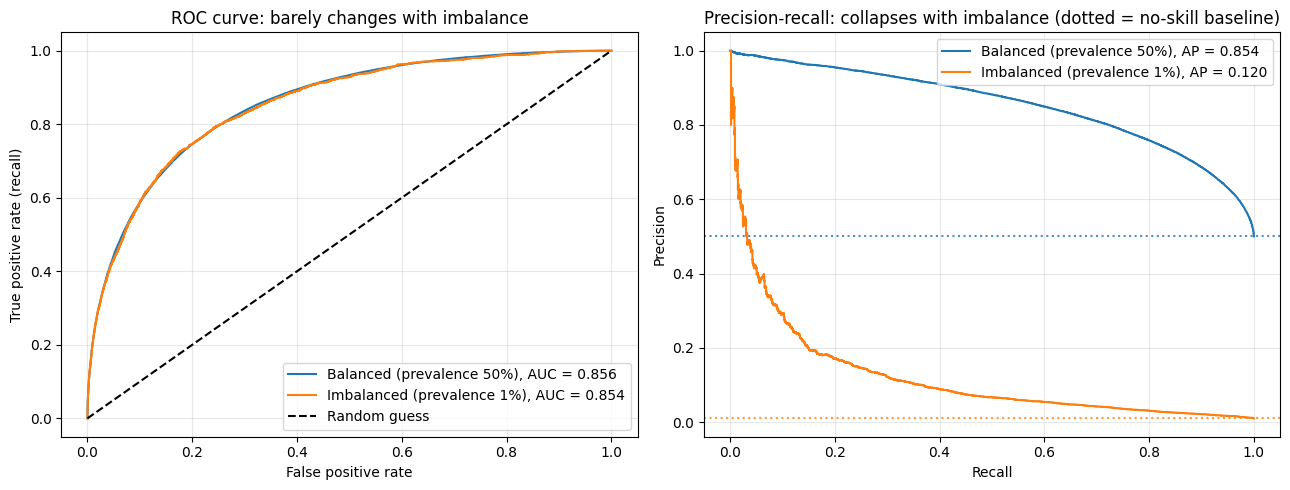

In [5]:
def make_scores(n, prev):
    y = (rng.random(n) < prev).astype(int)
    s = rng.normal(loc=np.where(y == 1, 1.5, 0.0), scale=1.0)
    return y, s

datasets = {"Balanced (prevalence 50%)": make_scores(200_000, 0.50),
            "Imbalanced (prevalence 1%)": make_scores(200_000, 0.01)}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, (y, s) in datasets.items():
    fpr, tpr, _ = roc_curve(y, s)
    prec, rec, _ = precision_recall_curve(y, s)
    roc_auc = auc(fpr, tpr)
    ap = average_precision_score(y, s)
    axes[0].plot(fpr, tpr, label=f"{name}, AUC = {roc_auc:.3f}")
    line, = axes[1].plot(rec, prec, label=f"{name}, AP = {ap:.3f}")
    axes[1].axhline(y.mean(), color=line.get_color(), linestyle=":", alpha=0.8)   # no-skill baseline = prevalence
    print(f"{name:<28} AUC-ROC = {roc_auc:.3f} | Average precision = {ap:.3f} | prevalence = {y.mean():.3f}")

axes[0].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curve: barely changes with imbalance"); axes[0].legend(loc="lower right"); axes[0].grid(alpha=0.3)

axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall: collapses with imbalance (dotted = no-skill baseline)")
axes[1].legend(loc="upper right"); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

Fix the operating point at recall (TPR) $\ge 0.90$ and compare precision in the two populations:

In [6]:
for name, (y, s) in datasets.items():
    fpr, tpr, thr = roc_curve(y, s)
    i = np.argmax(tpr >= 0.90)                 # first threshold reaching TPR >= 0.90
    t = thr[i]
    pred = (s >= t).astype(int)
    tp = np.sum((pred == 1) & (y == 1)); fp = np.sum((pred == 1) & (y == 0))
    fn = np.sum((pred == 0) & (y == 1)); tn = np.sum((pred == 0) & (y == 0))
    pi = y.mean()
    prec_theory = tpr[i] * pi / (tpr[i] * pi + fpr[i] * (1 - pi))
    print(f"{name:<28} threshold={t:.2f} | TPR={tpr[i]:.3f} | FPR={fpr[i]:.3f} | "
          f"precision={tp/(tp+fp):.3f} (formula {prec_theory:.3f})")

Balanced (prevalence 50%)    threshold=0.22 | TPR=0.900 | FPR=0.411 | precision=0.686 (formula 0.686)
Imbalanced (prevalence 1%)   threshold=0.21 | TPR=0.900 | FPR=0.417 | precision=0.021 (formula 0.021)


**Interpretation (write this in an exam):** with the same classifier, TPR and FPR are unchanged, yet precision at TPR $\ge 0.90$ drops from about 0.69 to about 0.02 when positives are only 1% of the data. The ROC curve looks the same and therefore *hides* the imbalance, while the precision-recall curve exposes it. Under heavy class imbalance, report precision-recall / average precision (and compare against the prevalence baseline) alongside ROC-AUC. Accuracy is misleading too: predicting "negative" for everyone is 99% accurate at $\pi=0.01$.